# Oxygen meets the fragment-state approach: H₂O from OH and H₂

**Question.** In H₃, building the Hamiltonian from exact *fragment states* (the London equation) beat a learned orbital-level Hamiltonian with no target data. Does that survive a real heavy atom? Oxygen brings an atomic multiplet (³P, ¹D, ¹S), directional p orbitals, and many OH states.

**Model: covalent diatomics-in-molecules (DIM).** The polyatomic basis is every O(2p⁴) determinant times the spin of each H: 15 × 2 × 2 = 60 states.

$$\hat H_{\rm DIM}=\hat H_{\rm OH_a}+\hat H_{\rm OH_b}+\hat H_{\rm H_aH_b}-\hat H_{\rm O}-\hat H_{\rm H_a}-\hat H_{\rm H_b}$$

Each fragment operator is $\sum_n E_n(r)\,\hat P_n$, the sum over its states of exact energy × projector. An OH state is identified by three quantum numbers: the O term it comes from, |Λ| along the bond, and the pair spin. That gives eight OH states:

| O term + H | OH states |
|---|---|
| ³P + ²S | ²Σ⁻, ²Π (X), ⁴Σ⁻, ⁴Π |
| ¹D + ²S | ²Σ⁺ (A), ²Π, ²Δ |
| ¹S + ²S | ²Σ⁺ |

**No H₂O data enters the model.** Only O and H atom energies, eight OH curves and the two H₂ curves.

**References.** Frozen-core FCI in 6-31G for every atom, fragment and H₂O geometry. That is exact within this small basis, so all models are compared on equal terms; absolute bond energies are smaller than experiment because of the basis.

**Prior work.** DIM for water has a history. A 1998 study found that ionic (O⁻H⁺) structures and multicentre charge corrections were needed for a quantitative water surface, and DIM was later extended to water clusters by mixing OH and O⁻H⁺ valence-bond states. This notebook rebuilds the covalent version deliberately, to measure how large the gap is and how much of it a small learned correction can recover.

In [1]:
import os, time, numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
KCAL = 627.5095
C1, C2, C3, C4, C5, CREF = '#2a78d6', '#eb6834', '#1baf7a', '#e87ba4', '#7a5a00', '#3d3d3a'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'lines.linewidth': 2, 'font.size': 10, 'legend.frameon': False})

## 1 · Exact references

`fc_fci` runs frozen-core FCI (O 1s frozen) using orbitals from a closed-shell RHF on the same nuclei, so every fragment and every H₂O geometry shares one consistent recipe. OH states are labelled with C₂ᵥ symmetry: Σ⁺→A₁, Σ⁻→A₂, Π→B₁, and Δ appears once in A₁ and once in A₂.

Generating everything takes roughly 30–60 minutes on a laptop, so the results are cached in `h2o_refs.npz`; the generation code is kept here so you can rerun or extend it.

In [2]:
import time, numpy as np
from pyscf import gto, scf, mcscf, fci

BASIS = '6-31g'

def fc_fci(atom, charge, na, nb, nroots=1, ss=None, sym=None, wfnsym=None, ref_charge=None):
    """Frozen-core (O 1s) FCI. Orbitals from closed-shell RHF of the same nuclei with ref_charge."""
    spin = na - nb
    kw = dict(atom=atom, basis=BASIS, verbose=0, unit='Angstrom')
    if sym:
        kw.update(symmetry=True, symmetry_subgroup=sym)
    mol = gto.M(charge=charge, spin=spin, **kw)
    ref = gto.M(charge=ref_charge, spin=0, **kw)
    mf_ref = scf.RHF(ref).run()
    mf = scf.RHF(mol) if spin == 0 else scf.ROHF(mol)
    ncore = 1 if 'O' in atom else 0
    ncas = mol.nao - ncore
    mc = mcscf.CASCI(mf, ncas, (na - ncore, nb - ncore))
    mc.fcisolver.nroots = nroots
    if wfnsym is not None:
        mc.fcisolver.wfnsym = wfnsym
    if ss is not None:
        mc.fcisolver = fci.addons.fix_spin_(mc.fcisolver, ss=ss, shift=0.5)
    mc.fcisolver.conv_tol = 1e-10
    mc.verbose = 0
    e = mc.kernel(mf_ref.mo_coeff)[0]
    return np.atleast_1d(e)



In [3]:
def oh_states(r):
    # all eight valence OH states at bond length r (Angstrom)
    at = f'O 0 0 0; H 0 0 {r}'
    a1 = fc_fci(at, 0, 5, 4, nroots=5, ss=0.75, sym='C2v', wfnsym='A1', ref_charge=-1)
    a2 = fc_fci(at, 0, 5, 4, nroots=3, ss=0.75, sym='C2v', wfnsym='A2', ref_charge=-1)
    b1 = fc_fci(at, 0, 5, 4, nroots=3, ss=0.75, sym='C2v', wfnsym='B1', ref_charge=-1)
    q2 = fc_fci(at, 0, 6, 3, nroots=2, ss=3.75, sym='C2v', wfnsym='A2', ref_charge=-1)
    qb = fc_fci(at, 0, 6, 3, nroots=2, ss=3.75, sym='C2v', wfnsym='B1', ref_charge=-1)
    d = [np.min(np.abs(a1 - e)) for e in a2]                    # Delta: the A2 root with an A1 partner
    delta, sig_minus = a2[int(np.argmin(d))], np.delete(a2, int(np.argmin(d)))[0]
    sig_plus = np.delete(a1, int(np.argmin(np.abs(a1 - delta))))  # drop only the Delta's A1 component
    return {'2S-': sig_minus, '2P1': b1[0], '2P2': b1[1], '4S-': q2[0], '4P': qb[0],
            '2S+1': sig_plus[0], '2S+2': sig_plus[1], '2D': delta}

def h2o_energy(r1, r2, theta):
    t = np.radians(theta)
    at = f'O 0 0 0; H {r1} 0 0; H {r2 * np.cos(t)} {r2 * np.sin(t)} 0'
    return fc_fci(at, 0, 5, 5, ss=0, sym='Cs', wfnsym="A'", ref_charge=0)[0]

if not os.path.exists('h2o_refs.npz'):
    print('computing references: this takes a while')
    ref = {'E_O3P': fc_fci('O 0 0 0', 0, 5, 3, ss=2, ref_charge=-2)[0]}
    eOs = fc_fci('O 0 0 0', 0, 4, 4, nroots=6, ss=0, ref_charge=-2)
    ref['E_O1D'], ref['E_O1S'] = eOs[0], eOs[5]
    ref['E_H'] = fc_fci('H 0 0 0', 0, 1, 0, ref_charge=-1)[0]
    ref['r_di'] = r_di = np.concatenate([np.arange(0.55, 2.0, 0.05), np.arange(2.0, 4.0, 0.2), np.arange(4.0, 8.01, 1.0)])
    st = [oh_states(r) for r in r_di]
    for k in st[0]:
        ref['OH_' + k] = np.array([s[k] for s in st])
    ref['H2_S'] = np.array([fc_fci(f'H 0 0 0; H 0 0 {r}', 0, 1, 1, ss=0, ref_charge=0)[0] for r in r_di])
    ref['H2_T'] = np.array([fc_fci(f'H 0 0 0; H 0 0 {r}', 0, 2, 0, ss=2, ref_charge=0)[0] for r in r_di])
    rg = [0.75, 0.85, 0.96, 1.1, 1.25, 1.45, 1.7, 2.0, 2.4, 2.9, 3.5]
    geo = [(a, b, 104.5) for i, a in enumerate(rg) for b in rg[i:]]
    geo += [(0.96, 0.96, th) for th in range(40, 181, 10)] + [(1.4, 1.4, th) for th in range(40, 181, 20)]
    rng = np.random.default_rng(0)
    geo += [(rng.uniform(0.75, 2.5), rng.uniform(0.75, 2.5), rng.uniform(60, 180)) for _ in range(60)]
    ref['h2o_geo'] = np.array(geo)
    ref['h2o_tag'] = np.array(['grid'] * 66 + ['bend096'] * 15 + ['bend14'] * 8 + ['random'] * 60)
    ref['h2o_E'] = np.array([h2o_energy(*g) for g in geo])
    np.savez('h2o_refs.npz', **ref)
ref = dict(np.load('h2o_refs.npz'))
geo, E_fci, tag = ref['h2o_geo'], ref['h2o_E'], ref['h2o_tag']
E_atoms = ref['E_O3P'] + 2 * ref['E_H']
print(f"O: 1D - 3P = {(ref['E_O1D'] - ref['E_O3P']) * 27.2114:.2f} eV, 1S - 3P = {(ref['E_O1S'] - ref['E_O3P']) * 27.2114:.2f} eV")
print(f'{len(geo)} H2O geometries; FCI atomisation energy at the best grid point: {-(E_fci.min() - E_atoms) * KCAL:.1f} kcal/mol')

O: 1D - 3P = 2.24 eV, 1S - 3P = 3.89 eV
149 H2O geometries; FCI atomisation energy at the best grid point: 179.4 kcal/mol


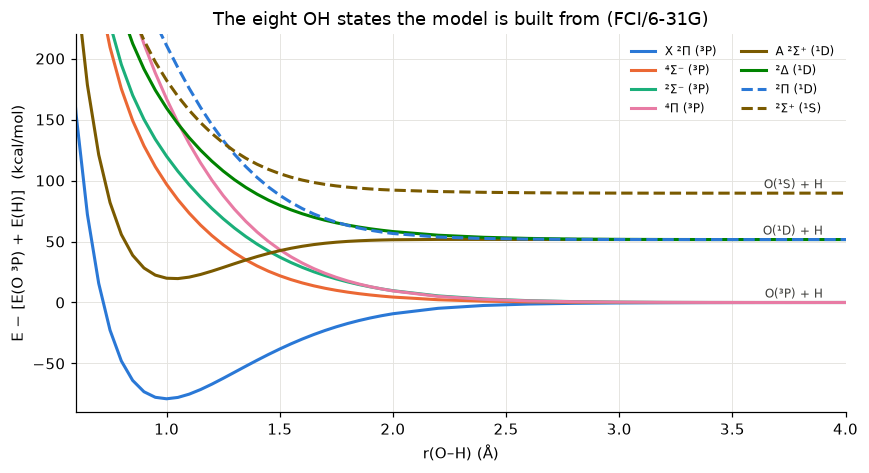

In [4]:
names = {'2P1': 'X ²Π (³P)', '4S-': '⁴Σ⁻ (³P)', '2S-': '²Σ⁻ (³P)', '4P': '⁴Π (³P)',
         '2S+1': 'A ²Σ⁺ (¹D)', '2D': '²Δ (¹D)', '2P2': '²Π (¹D)', '2S+2': '²Σ⁺ (¹S)'}
cols = {'2P1': C1, '4S-': C2, '2S-': C3, '4P': C4, '2S+1': C5, '2D': '#008300', '2P2': C1, '2S+2': C5}   # dashed = second state of the same symmetry
E0 = ref['E_O3P'] + ref['E_H']
fig, ax = plt.subplots(figsize=(8, 4.4))
for k in names:
    ls = '--' if k in ('2P2', '2S+2') else '-'
    ax.plot(ref['r_di'], (ref['OH_' + k] - E0) * KCAL, color=cols[k], ls=ls, label=names[k])
for t, lab in [('E_O1D', 'O(¹D) + H'), ('E_O1S', 'O(¹S) + H')]:
    ax.text(3.9, (ref[t] - ref['E_O3P']) * KCAL + 4, lab, ha='right', fontsize=8, color=CREF)
ax.text(3.9, 4, 'O(³P) + H', ha='right', fontsize=8, color=CREF)
ax.set(xlim=(0.6, 4), ylim=(-90, 220), xlabel='r(O–H) (Å)', ylabel='E − [E(O ³P) + E(H)]  (kcal/mol)',
       title='The eight OH states the model is built from (FCI/6-31G)')
ax.legend(fontsize=8, ncol=2, loc='upper right')
plt.tight_layout(); plt.savefig('h2o_fig1_oh_states.png', bbox_inches='tight'); plt.show()

## 2 · The DIM model

O(2p⁴) operators are built from Jordan–Wigner fermions on the six p spin-orbitals. The ingredients:

- **O term projectors:** joint eigenspaces of L² and S².
- **|Λ| along each bond:** eigenspaces of (n̂·L)².
- **Pair spin:** eigenspaces of (S_O + s_H)².

Each OH state projector is a product of the three. Same-symmetry states from different O terms (the two ²Π, the two ²Σ⁺) are *not* mixed here, so that mixing is the obvious learnable correction later. The coupling operators that would mix them are built now:

- **²Π block:** the exchange of the H spin with the spin in O's p orbital along the bond.
- **²Σ⁺ block:** the occupation of that p orbital.

Both commute with Λ and the pair spin, as they must.

In [5]:
"""Covalent diatomics-in-molecules (DIM) model for H2O built from OH and H2 fragment states.

Polyatomic basis: O(2p^4) determinants (15) x H_a spin (2) x H_b spin (2) = 60 states.
H_DIM = H_OHa + H_OHb + H_HH - H_O - H_Ha - H_Hb, each fragment operator written as
sum_states E_state(r) * P_state, with P_state built from O term, |Lambda| along the bond, and pair spin.
"""
import itertools
import numpy as np
from scipy.interpolate import CubicSpline

# ---------- O 2p^4 space ----------
def _jw(nso):
    I2, Z = np.eye(2), np.diag([1.0, -1.0])
    a1 = np.array([[0.0, 1.0], [0.0, 0.0]])
    ops = []
    for p in range(nso):
        m = np.array([[1.0]])
        for q in range(nso):
            m = np.kron(m, Z if q < p else (a1 if q == p else I2))
        ops.append(m)
    return ops

_a = _jw(6)                                  # spin orbital p = 2*k + sigma, k in (x, y, z)
_ad = [x.T for x in _a]
_occ = np.array([[(s >> (5 - p)) & 1 for p in range(6)] for s in range(64)])
_keep = np.where(_occ.sum(1) == 4)[0]
_P = lambda M: M[np.ix_(_keep, _keep)]

def _one_body(h):                            # spin-free one-body operator from 3x3 spatial matrix
    M = np.zeros((64, 64), dtype=complex)
    for i in range(3):
        for j in range(3):
            if h[i, j] != 0:
                for s in (0, 1):
                    M += h[i, j] * _ad[2 * i + s] @ _a[2 * j + s]
    return _P(M)

eps = np.zeros((3, 3, 3))
for i, j, k in itertools.permutations(range(3)):
    eps[i, j, k] = np.linalg.det(np.eye(3)[[i, j, k]])
L_O = [_one_body(-1j * eps[k]) for k in range(3)]          # (l_k)_{ij} = -i eps_{kij}
Sz_O = _P(sum(0.5 * (_ad[2 * k] @ _a[2 * k] - _ad[2 * k + 1] @ _a[2 * k + 1]) for k in range(3))).astype(complex)
Sp_O = _P(sum(_ad[2 * k] @ _a[2 * k + 1] for k in range(3))).astype(complex)
S_O = [(Sp_O + Sp_O.conj().T) / 2, (Sp_O - Sp_O.conj().T) / 2j, Sz_O]
NO = 15

def p_along(n):                              # occupation of the p orbital pointing along unit vector n
    return _one_body(np.outer(n, n).astype(complex))

def spin_along(n):
    """Spin vector of the electrons in the p orbital pointing along n (a spin-rank-1 O operator)."""
    pauli = [np.array([[0, 1], [1, 0]]) / 2, np.array([[0, -1j], [1j, 0]]) / 2, np.diag([0.5, -0.5])]
    out = []
    for sk in pauli:
        M = np.zeros((64, 64), dtype=complex)
        for i in range(3):
            for j in range(3):
                if n[i] * n[j] == 0:
                    continue
                for s1 in (0, 1):
                    for s2 in (0, 1):
                        if sk[s1, s2] != 0:
                            M += n[i] * n[j] * sk[s1, s2] * _ad[2 * i + s1] @ _a[2 * j + s2]
        out.append(_P(M))
    return out

# ---------- product space O x Ha x Hb ----------
sh = [np.array([[0, 1], [1, 0]]) / 2, np.array([[0, -1j], [1j, 0]]) / 2, np.diag([0.5, -0.5])]
I2, I4, IO = np.eye(2), np.eye(4), np.eye(NO)
embO = lambda M: np.kron(M, I4)
embA = lambda m: np.kron(IO, np.kron(m, I2))
embB = lambda m: np.kron(IO, np.kron(I2, m))
DIM = 60

def sq(vec):                                 # V.V for a 3-vector of operators
    return sum(v @ v for v in vec)

def projector(M, value, tol=1e-6):
    w, U = np.linalg.eigh((M + M.conj().T) / 2)
    sel = np.abs(w - value) < tol
    P = U[:, sel] @ U[:, sel].conj().T
    assert np.abs(P.imag).max() < 1e-10   # every operator used here is real-symmetric in this basis
    return P.real

TERM_M = embO(sq(L_O) + 10 * sq(S_O))
P_TERM = {'3P': projector(TERM_M, 22), '1D': projector(TERM_M, 6), '1S': projector(TERM_M, 0)}
S_A = [embO(S_O[k]) + embA(sh[k]) for k in range(3)]
S_B = [embO(S_O[k]) + embB(sh[k]) for k in range(3)]
S_HH = [embA(sh[k]) + embB(sh[k]) for k in range(3)]
S_TOT = [embO(S_O[k]) + embA(sh[k]) + embB(sh[k]) for k in range(3)]
P_SA = {0.5: projector(sq(S_A), 0.75), 1.5: projector(sq(S_A), 3.75)}
P_SB = {0.5: projector(sq(S_B), 0.75), 1.5: projector(sq(S_B), 3.75)}
P_HH = {'S': projector(sq(S_HH), 0.0), 'T': projector(sq(S_HH), 2.0)}
w_tot, U_tot = np.linalg.eigh(sq(S_TOT).real)
SINGLET = U_tot[:, np.abs(w_tot) < 1e-6]     # basis of total-singlet states

# OH fragment states: (O term, pair spin, |Lambda|) -> curve key
CLASSES = {('3P', 0.5, 0): '2S-', ('3P', 0.5, 1): '2P1', ('3P', 1.5, 0): '4S-', ('3P', 1.5, 1): '4P',
           ('1D', 0.5, 0): '2S+1', ('1D', 0.5, 1): '2P2', ('1D', 0.5, 2): '2D', ('1S', 0.5, 0): '2S+2'}
EXPECTED_RANK = {'2S-': 2, '2P1': 4, '4S-': 4, '4P': 8, '2S+1': 2, '2P2': 4, '2D': 4, '2S+2': 2}

def oh_projectors(n, P_S, emb_h):
    """Fragment-state projectors and 3P/1D (Pi) and 1D/1S (Sigma+) coupling operators for one OH pair."""
    nL = embO(sum(n[k] * L_O[k] for k in range(3)))
    lam2 = (nL @ nL)
    P_lam = {l: projector(lam2, l * l) for l in (0, 1, 2)}
    P = {}
    for (term, s, lam), key in CLASSES.items():
        P[key] = (P_TERM[term] @ P_lam[lam] @ P_S[s]).real
    # coupling between same-symmetry states from different O terms:
    # Pi block (O triplet <-> O singlet) via exchange of the H spin with the O p-sigma spin,
    # Sigma+ block (both O singlets) via occupation of the p-sigma orbital
    T = spin_along(n)
    ops = {('2P1', '2P2'): sum(embO(T[k]) @ emb_h(sh[k]) for k in range(3)),
           ('2S+1', '2S+2'): embO(p_along(n))}
    coup = {}
    for (ka, kb), C in ops.items():
        Cab = P[kb] @ C @ P[ka]
        assert np.abs(Cab.imag).max() < 1e-10
        Cab = Cab.real
        sv = np.linalg.svd(Cab, compute_uv=False)
        c = sv[sv > 1e-8]
        assert np.allclose(c, c[0]), (ka, kb, c)
        coup[(ka, kb)] = (Cab + Cab.T) / c[0]
    return P, coup

class Curves:
    """Spline interpolation of fragment curves, relative to their separated-atom limits."""
    def __init__(self, ref):
        r = ref['r_di']
        self.EO = {'3P': ref['E_O3P'], '1D': ref['E_O1D'], '1S': ref['E_O1S']}
        self.EH = ref['E_H']
        self.rmax = r[-1]
        asym = {'2S-': '3P', '2P1': '3P', '4S-': '3P', '4P': '3P', '2S+1': '1D', '2P2': '1D', '2D': '1D', '2S+2': '1S'}
        self.asym = {k: self.EO[t] + self.EH for k, t in asym.items()}
        self.oh = {k: CubicSpline(r, ref['OH_' + k] - self.asym[k]) for k in CLASSES.values()}
        self.hh = {s: CubicSpline(r, ref['H2_' + s] - 2 * self.EH) for s in ('S', 'T')}
    def OH(self, key, r):
        return self.asym[key] + (self.oh[key](r) if r < self.rmax else 0.0)
    def HH(self, s, r):
        return 2 * self.EH + (self.hh[s](r) if r < self.rmax else 0.0)

def coords(r1, r2, theta_deg):
    t = np.radians(theta_deg)
    return np.array([[0, 0, 0], [r1, 0, 0], [r2 * np.cos(t), r2 * np.sin(t), 0]], float)

class Geometry:
    """Everything about one H2O geometry that does not depend on learned parameters."""
    def __init__(self, r1, r2, theta):
        X = coords(r1, r2, theta)
        self.r = [np.linalg.norm(X[1] - X[0]), np.linalg.norm(X[2] - X[0]), np.linalg.norm(X[2] - X[1])]
        self.Pa, self.Ca = oh_projectors((X[1] - X[0]) / self.r[0], P_SA, embA)
        self.Pb, self.Cb = oh_projectors((X[2] - X[0]) / self.r[1], P_SB, embB)
        # every fragment operator conserves total spin, so work in the 9-dim total-singlet space
        red = lambda M: SINGLET.T @ M @ SINGLET
        self.sPa = {k: red(v) for k, v in self.Pa.items()}
        self.sPb = {k: red(v) for k, v in self.Pb.items()}
        self.sCa = {k: red(v) for k, v in self.Ca.items()}
        self.sCb = {k: red(v) for k, v in self.Cb.items()}

def hamiltonian(g, cv, phi=None):
    """DIM Hamiltonian; phi(r) -> dict of mixing angles for ('2P1','2P2') and ('2S+1','2S+2') blocks."""
    H = np.zeros((DIM, DIM))
    for P, C, r in [(g.Pa, g.Ca, g.r[0]), (g.Pb, g.Cb, g.r[1])]:
        E = {k: cv.OH(k, r) for k in P}
        ang = phi(r) if phi is not None else {}
        for k, Pk in P.items():
            H += E[k] * Pk
        for (ka, kb), Cn in C.items():
            f = ang.get((ka, kb), 0.0)
            if f == 0.0:
                continue
            c, s = np.cos(f), np.sin(f)
            # rotate the adiabatic pair: lower state = c|a> + s|b>
            H += (E[ka] * (c * c - 1) + E[kb] * s * s) * P[ka] + (E[ka] * s * s + E[kb] * (c * c - 1)) * P[kb]
            H += (E[ka] - E[kb]) * c * s * Cn
    H += cv.HH('S', g.r[2]) * P_HH['S'] + cv.HH('T', g.r[2]) * P_HH['T']
    H -= sum(cv.EO[t] * P_TERM[t].real for t in P_TERM) + 2 * cv.EH * np.eye(DIM)
    return H

S_PHH = {k: SINGLET.T @ v @ SINGLET for k, v in P_HH.items()}
S_PTERM = {k: SINGLET.T @ v @ SINGLET for k, v in P_TERM.items()}

def singlet_ground(g, cv, phi=None):
    """Lowest singlet of H_DIM, assembled directly in the singlet subspace (same result as hamiltonian())."""
    H = np.zeros((SINGLET.shape[1],) * 2)
    for P, C, r in [(g.sPa, g.sCa, g.r[0]), (g.sPb, g.sCb, g.r[1])]:
        E = {k: cv.OH(k, r) for k in P}
        for k, Pk in P.items():
            H += E[k] * Pk
        ang = phi(r) if phi is not None else {}
        for (ka, kb), Cn in C.items():
            f = ang.get((ka, kb), 0.0)
            if f == 0.0:
                continue
            c, s = np.cos(f), np.sin(f)
            H += (E[ka] * (c * c - 1) + E[kb] * s * s) * P[ka] + (E[ka] * s * s + E[kb] * (c * c - 1)) * P[kb]
            H += (E[ka] - E[kb]) * c * s * Cn
    H += cv.HH('S', g.r[2]) * S_PHH['S'] + cv.HH('T', g.r[2]) * S_PHH['T']
    H -= sum(cv.EO[t] * S_PTERM[t] for t in S_PTERM) + 2 * cv.EH * np.eye(len(H))
    return np.linalg.eigvalsh(H)[0]

def singlet_ground_full(g, cv, phi=None):
    H = hamiltonian(g, cv, phi)
    return np.linalg.eigvalsh(SINGLET.T @ H @ SINGLET)[0]

def pairwise(r1, r2, theta, cv):
    """Bond-additivity baseline: two OH X2Pi bonds plus H-H triplet repulsion."""
    g = coords(r1, r2, theta)
    r3 = np.linalg.norm(g[2] - g[1])
    return (cv.EO['3P'] + 2 * cv.EH + (cv.OH('2P1', r1) - cv.asym['2P1']) + (cv.OH('2P1', r2) - cv.asym['2P1'])
            + cv.HH('T', r3) - 2 * cv.EH)



In [6]:
cv = Curves(ref)
g = Geometry(0.96, 1.1, 104.5)
print('state       rank  expected')
for k, Pk in g.Pa.items():
    print(f'{k:8s} {int(round(np.trace(Pk))):6d} {2 * EXPECTED_RANK[k]:8d}')
print('projectors complete:', np.allclose(sum(g.Pa.values()), np.eye(DIM)), '| total-singlet states:', SINGLET.shape[1])
print(f"one H far:  DIM − [E(OH X²Π) + E(H)] = {(singlet_ground(Geometry(1.0, 40, 104.5), cv) - cv.OH('2P1', 1.0) - cv.EH) * KCAL:.1e} kcal/mol")
print(f'both far:   DIM − [E(O) + 2E(H)]      = {(singlet_ground(Geometry(40, 40, 104.5), cv) - E_atoms) * KCAL:.1e} kcal/mol')

state       rank  expected
2S-           4        4
2P1           8        8
4S-           8        8
4P           16       16
2S+1          4        4
2P2           8        8
2D            8        8
2S+2          4        4
projectors complete: True | total-singlet states: 9
one H far:  DIM − [E(OH X²Π) + E(H)] = -4.6e-11 kcal/mol
both far:   DIM − [E(O) + 2E(H)]      = -6.2e-11 kcal/mol


## 3 · DIM vs exact H₂O, with no H₂O data

Also shown: a bond-additivity baseline (two OH X²Π bonds plus H–H triplet repulsion), the simplest thing a fragment model could do.

In [7]:
t0 = time.time()
GEOMS = [Geometry(*x) for x in geo]
E_dim = np.array([singlet_ground(g, cv) for g in GEOMS])
E_pair = np.array([pairwise(*x, cv) for x in geo])
rel = lambda E: (E - E_atoms) * KCAL
def rmse(a, b, m=slice(None)):
    return np.sqrt(np.mean(((a - b)[m] * KCAL) ** 2))
print(f'{len(geo)} geometries in {time.time() - t0:.1f} s')
for nm, E in [('DIM', E_dim), ('bond additivity', E_pair)]:
    print(f'{nm:16s} RMSE all {rmse(E, E_fci):6.1f}  | ' + '  '.join(f'{t} {rmse(E, E_fci, tag == t):5.1f}' for t in np.unique(tag)))
i_eq = np.where((geo[:, 0] == 0.96) & (geo[:, 1] == 0.96) & (geo[:, 2] == 104.5))[0][0]
print(f'at r = 0.96 Å, 104.5°: FCI {rel(E_fci[i_eq]):.1f}, DIM {rel(E_dim[i_eq]):.1f}, bond additivity {rel(E_pair[i_eq]):.1f} kcal/mol')

149 geometries in 0.5 s
DIM              RMSE all   24.8  | bend096  46.2  bend14  33.5  grid  24.5  random  13.7
bond additivity  RMSE all   25.4  | bend096  47.6  bend14  37.8  grid  24.5  random  13.7
at r = 0.96 Å, 104.5°: FCI -178.9, DIM -133.3, bond additivity -133.3 kcal/mol


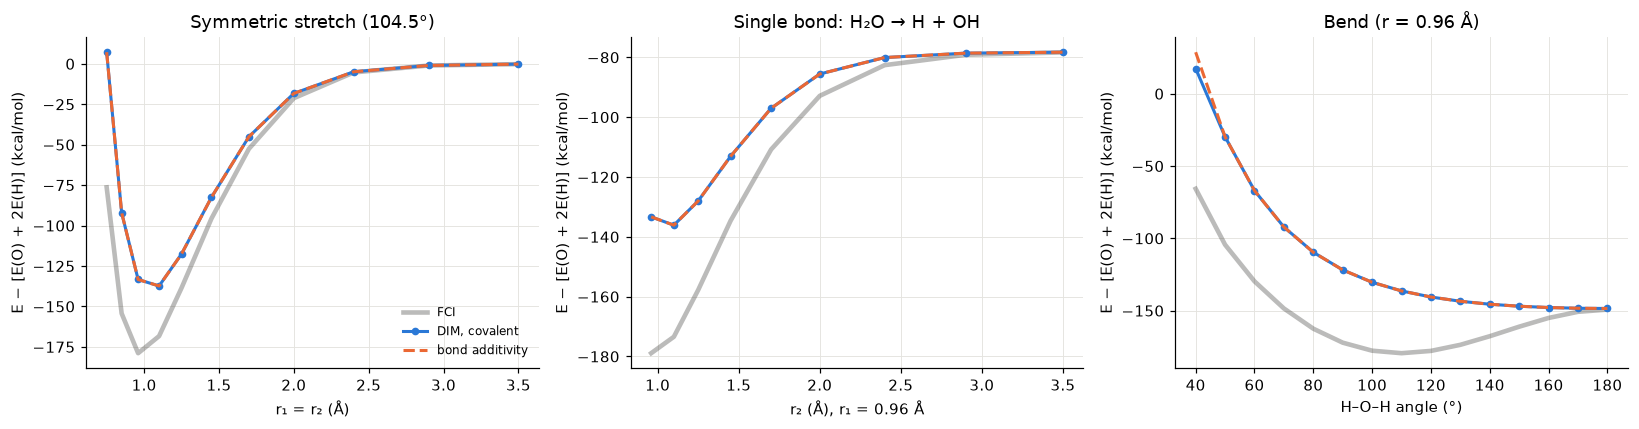

equilibrium angle on the r = 0.96 Å bend scan: FCI 110°, DIM 180°
max |DIM − bond additivity| for angles ≥ 60°: 0.00 kcal/mol


In [8]:
def scan(mask, key):
    idx = np.where(mask)[0]
    return idx[np.argsort(geo[idx, key])]
sym = scan((tag == 'grid') & (geo[:, 0] == geo[:, 1]), 0)
one = scan((tag == 'grid') & (geo[:, 0] == 0.96), 1)
bend = scan(tag == 'bend096', 2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, idx, x, xl, title in [(axes[0], sym, geo[sym, 0], 'r₁ = r₂ (Å)', 'Symmetric stretch (104.5°)'),
                              (axes[1], one, geo[one, 1], 'r₂ (Å), r₁ = 0.96 Å', 'Single bond: H₂O → H + OH'),
                              (axes[2], bend, geo[bend, 2], 'H–O–H angle (°)', 'Bend (r = 0.96 Å)')]:
    ax.plot(x, rel(E_fci[idx]), color=CREF, lw=3, alpha=0.35, label='FCI')
    ax.plot(x, rel(E_dim[idx]), color=C1, marker='o', ms=4, label='DIM, covalent')
    ax.plot(x, rel(E_pair[idx]), color=C2, ls='--', label='bond additivity')
    ax.set(xlabel=xl, ylabel='E − [E(O) + 2E(H)] (kcal/mol)', title=title)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('h2o_fig2_dim_scans.png', bbox_inches='tight'); plt.show()
ib = bend[np.argmin(E_fci[bend])]; jb = bend[np.argmin(E_dim[bend])]
print(f'equilibrium angle on the r = 0.96 Å bend scan: FCI {geo[ib, 2]:.0f}°, DIM {geo[jb, 2]:.0f}°')
print(f'max |DIM − bond additivity| for angles ≥ 60°: {np.max(np.abs(E_dim - E_pair)[geo[:, 2] >= 60]) * KCAL:.2f} kcal/mol')

**Why the bend is wrong.** With only O 2p orbitals, a configuration with two holes in the in-plane p orbitals has, *for any in-plane direction*, one hole along that axis and one perpendicular. That is the X²Π pattern seen from both H atoms simultaneously at every angle. Covalent DIM therefore gives two full OH bonds regardless of angle, coinciding with bond additivity, and only H–H repulsion shapes the bend, which favours linear. The real bend comes from what this basis leaves out: polar O⁻H⁺ character (lone-pair and charge effects) and 2s–2p hybridisation. This reproduces the literature's conclusion that ionic structures are essential for water.

## 4 · How much can a small learned correction recover?

All corrections use only target (H₂O) data. For each training-set size *n*, five random splits of all 149 geometries: train on *n*, test on the rest. (A first attempt that trained only on uniformly random bond lengths never sampled the equilibrium well, so every learned model was extrapolating into the most important region; random splits over everything mimic a dataset that includes near-equilibrium MD.) Plots show the median over splits with the full range as bars.

| Correction | What is learned | Parameters |
|---|---|---|
| **DIM + mixing angles** | ³P/¹D (²Π) and ¹D/¹S (²Σ⁺) mixing in each OH fragment, as short-range functions of r: a *fragment-level* quantity, transferable to any molecule containing OH | 10 |
| **DIM + Δ-KRR** | kernel ridge on the DIM residual | n |
| **plain KRR** | kernel ridge on the energy, no physics | n |

Both KRR models use the same permutation-invariant overlap-based descriptor.

In [9]:
import numpy as np
from scipy.optimize import least_squares

KCAL, BOHR = 627.5095, 0.529177
ZETAS = np.array([0.5, 0.8, 1.1, 1.5, 2.0])

def slater(r_ang):
    p = (r_ang / BOHR) * ZETAS
    return np.exp(-p) * (1 + p + p * p / 3)

def make_phi(c):
    """Learned 3P/1D (Pi) and 1D/1S (Sigma+) mixing angles of OH as functions of r. Vanish at large r."""
    cp, cs = c[:5], c[5:10]
    return lambda r: {('2P1', '2P2'): slater(r) @ cp, ('2S+1', '2S+2'): slater(r) @ cs}

def fit_phi(geoms, E, cv, ridge=0.3, c0=None):
    def resid(c):
        phi = make_phi(c)
        pred = np.array([singlet_ground(g, cv, phi) for g in geoms])
        return np.concatenate([(pred - E) * KCAL, np.sqrt(ridge) * c])
    return least_squares(resid, np.zeros(10) if c0 is None else c0, method='trf', x_scale='jac', max_nfev=100).x

def features(x):
    """Permutation-invariant H2O descriptor from Slater overlaps (the descriptor family that interpolated best)."""
    r1, r2, th = x
    X = coords(r1, r2, th)
    r3 = np.linalg.norm(X[2] - X[1])
    s1, s2, s3 = slater(r1)[[0, 2, 4]], slater(r2)[[0, 2, 4]], slater(r3)[[0, 2, 4]]
    return np.concatenate([s1 + s2, s1 * s2, s3])

class KRR:
    """RBF kernel ridge; hyperparameters by 5-fold cross-validation on the training set (regularisation floor 1e-6)."""
    def fit(self, X, y, seed=0):
        self.m, self.s = X.mean(0), X.std(0) + 1e-9
        Z = (X - self.m) / self.s
        self.mu = y.mean()
        yc = y - self.mu
        folds = np.array_split(np.random.default_rng(seed).permutation(len(Z)), min(5, len(Z)))
        D2 = ((Z[:, None] - Z[None]) ** 2).sum(-1)
        best = (np.inf, None)
        for g in np.geomspace(1e-3, 3, 12):
            K = np.exp(-g * D2)
            for lam in np.geomspace(1e-6, 1, 7):
                err = 0.0
                for f in folds:
                    tr = np.setdiff1d(np.arange(len(Z)), f)
                    w = np.linalg.solve(K[np.ix_(tr, tr)] + lam * np.eye(len(tr)), yc[tr])
                    err += np.sum((K[np.ix_(f, tr)] @ w - yc[f]) ** 2)
                if err < best[0]:
                    best = (err, (g, lam))
        self.g, lam = best[1]
        self.Z = Z
        self.w = np.linalg.solve(np.exp(-self.g * D2) + lam * np.eye(len(Z)), yc)
        return self
    def predict(self, X):
        Z = (X - self.m) / self.s
        return np.exp(-self.g * ((Z[:, None] - self.Z[None]) ** 2).sum(-1)) @ self.w + self.mu


In [10]:
allidx = np.arange(len(geo))
FEAT = np.array([features(x) for x in geo])
ns = [5, 10, 20, 40, 80]
res = {'DIM + mixing angles': [], 'DIM + Δ-KRR': [], 'plain KRR': []}
keep = {}
t0 = time.time()
for n in ns:
    r_m, r_d, r_k = [], [], []
    for seed in range(5):
        sel = np.random.default_rng(seed).choice(allidx, n, replace=False)
        test = np.setdiff1d(allidx, sel)
        c = fit_phi([GEOMS[i] for i in sel], E_fci[sel], cv)
        Em = np.array([singlet_ground(GEOMS[i], cv, make_phi(c)) for i in test])
        r_m.append(rmse(Em, E_fci[test]))
        kd = KRR().fit(FEAT[sel], (E_fci[sel] - E_dim[sel]) * KCAL)
        r_d.append(rmse(E_dim[test] + kd.predict(FEAT[test]) / KCAL, E_fci[test]))
        kp = KRR().fit(FEAT[sel], (E_fci[sel] - E_atoms) * KCAL)
        r_k.append(rmse(E_atoms + kp.predict(FEAT[test]) / KCAL, E_fci[test]))
        if n == 20 and seed == 0:
            keep = {'c': c, 'kd': kd, 'kp': kp, 'sel': sel}
    for k, v in zip(res, [r_m, r_d, r_k]):
        res[k].append(v)
    print(f'n = {n:2d}: ' + '  '.join(f'{k} {np.median(v):5.1f} [{np.min(v):.1f}–{np.max(v):.1f}]' for k, v in zip(res, [r_m, r_d, r_k])), f'({time.time() - t0:.0f} s)')
print(f'DIM with no H2O data: {rmse(E_dim, E_fci):.1f} kcal/mol over all geometries')

n =  5: DIM + mixing angles  18.6 [18.1–21.4]  DIM + Δ-KRR  16.7 [11.1–27.3]  plain KRR  35.2 [26.9–53.4] (2 s)
n = 10: DIM + mixing angles  20.6 [18.1–25.3]  DIM + Δ-KRR  12.0 [10.8–35.4]  plain KRR  31.6 [29.5–41.1] (5 s)
n = 20: DIM + mixing angles  21.1 [17.6–23.5]  DIM + Δ-KRR  10.7 [10.1–12.2]  plain KRR  24.3 [13.6–27.6] (12 s)
n = 40: DIM + mixing angles  19.4 [14.5–22.7]  DIM + Δ-KRR  12.7 [8.2–21.1]  plain KRR  17.1 [10.7–44.0] (27 s)
n = 80: DIM + mixing angles  18.9 [14.4–31.4]  DIM + Δ-KRR   5.7 [4.6–11.4]  plain KRR   9.3 [4.0–45.9] (57 s)
DIM with no H2O data: 24.8 kcal/mol over all geometries


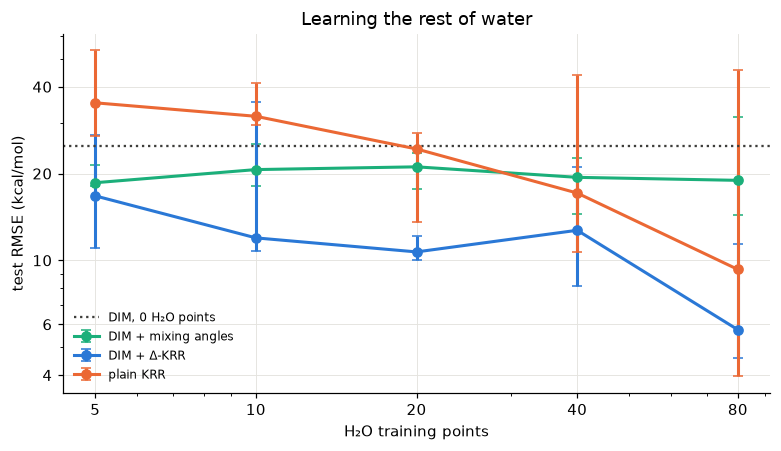

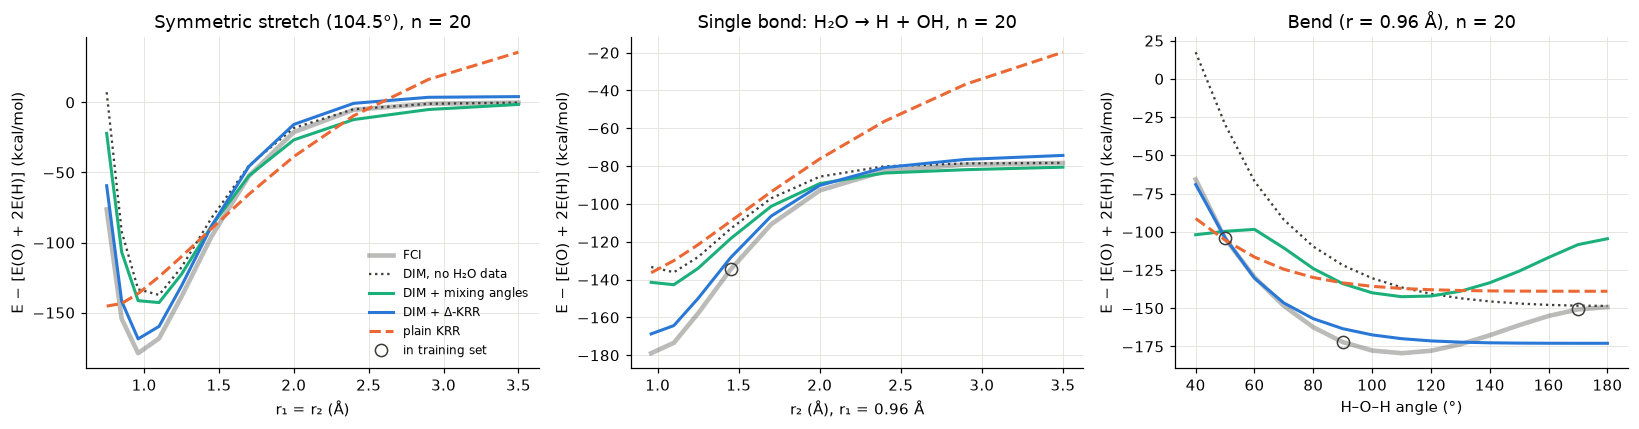

learned mixing angles at r = 0.96 Å (degrees): {'2P1/2P2': -15.6, '2S+1/2S+2': 54.0}


In [11]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for (lab, v), col in zip(res.items(), [C3, C1, C2]):
    med = np.array([np.median(x) for x in v])
    lo, hi = med - np.array([np.min(x) for x in v]), np.array([np.max(x) for x in v]) - med
    ax.errorbar(ns, med, yerr=[lo, hi], color=col, marker='o', ms=6, capsize=3, label=lab)
ax.axhline(rmse(E_dim, E_fci), color=CREF, ls=':', lw=1.5, label='DIM, 0 H₂O points')
ax.set(xscale='log', yscale='log', xlabel='H₂O training points', ylabel='test RMSE (kcal/mol)',
       title='Learning the rest of water')
ax.set_xticks(ns); ax.set_xticklabels(ns); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([4, 6, 10, 20, 40]); ax.set_yticklabels([4, 6, 10, 20, 40]); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('h2o_fig3_fewshot.png', bbox_inches='tight'); plt.show()

# the three scans again with n = 20 corrections
Em = np.array([singlet_ground(g, cv, make_phi(keep['c'])) for g in GEOMS])
Ed = E_dim + keep['kd'].predict(FEAT) / KCAL
Ek = E_atoms + keep['kp'].predict(FEAT) / KCAL
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, idx, x, xl, title in [(axes[0], sym, geo[sym, 0], 'r₁ = r₂ (Å)', 'Symmetric stretch (104.5°)'),
                              (axes[1], one, geo[one, 1], 'r₂ (Å), r₁ = 0.96 Å', 'Single bond: H₂O → H + OH'),
                              (axes[2], bend, geo[bend, 2], 'H–O–H angle (°)', 'Bend (r = 0.96 Å)')]:
    ax.plot(x, rel(E_fci[idx]), color=CREF, lw=3, alpha=0.35, label='FCI')
    ax.plot(x, rel(E_dim[idx]), color=CREF, ls=':', lw=1.5, label='DIM, no H₂O data')
    ax.plot(x, rel(Em[idx]), color=C3, label='DIM + mixing angles')
    ax.plot(x, rel(Ed[idx]), color=C1, label='DIM + Δ-KRR')
    ax.plot(x, rel(Ek[idx]), color=C2, ls='--', label='plain KRR')
    tr = np.isin(idx, keep['sel'])
    ax.plot(x[tr], rel(E_fci[idx][tr]), 'o', ms=8, mfc='none', mec=CREF, label='in training set')
    ax.set(xlabel=xl, ylabel='E − [E(O) + 2E(H)] (kcal/mol)', title=f'{title}, n = 20')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('h2o_fig4_corrections.png', bbox_inches='tight'); plt.show()
print('learned mixing angles at r = 0.96 Å (degrees):', {k[0] + '/' + k[1]: round(float(np.degrees(v)), 1) for k, v in make_phi(keep['c'])(0.96).items()})

## 5 · Takeaways

RMSE in kcal/mol against frozen-core FCI/6-31G over 149 H₂O geometries.

| Model | H₂O data | Error |
|---|---|---|
| Covalent DIM (OH and H₂ fragment states only) | 0 | 24.8 |
| Bond additivity (two OH X²Π bonds + H–H) | 0 | 25.4 |
| DIM + learned ³P/¹D and ¹D/¹S mixing (10 parameters) | 20 / 80 | 18.9 / 19.1 |
| DIM + Δ-KRR | 20 / 80 | 10.7 / 5.7 |
| Plain KRR, same descriptor | 20 / 80 | 24.3 / 9.3 |

Medians over five random splits; test errors on the held-out geometries.

1. **The machinery works.** Projectors built from O term, |Λ| and pair spin reproduce all eight OH states, and the separated-atom and H + OH limits come out exact. The single-bond channel is right once the bond is stretched past about 2.4 Å.
2. **Covalent fragment states are not enough for oxygen.** Water comes out underbound by 46 kcal/mol at equilibrium (133 vs 179) and linear instead of bent (180° vs 110°). For every angle above 60° the model is *identical* to bond additivity. With only O 2p orbitals, two in-plane holes look like an X²Π bond from any direction, so the basis carries no angular information. This is a cleaner statement of what the 1998 DIM work found empirically: ionic O⁻H⁺ structures are essential.
3. **The missing piece is not covalent-state mixing.** Learning the ³P/¹D and ¹D/¹S mixing in OH barely helps, and does not improve with more data. The error lives outside the covalent space, so no fragment-level correction *inside* it can recover it.
4. **The physics baseline still pays for itself.** Correcting DIM with a kernel model beats the same kernel model trained from scratch at every training-set size, by about half with 5–20 points and by 25–40% with 40–80. But the residual it has to learn reaches 84 kcal/mol, so here DIM is a helpful prior, not the near-complete answer London was for H₃.
5. **What this says about the method.** In H₃ the fragment states *were* the physics. In water, the fragment basis must include charge-transfer structures: O⁻(²P) + H⁺ alongside O(³P) + H. That is the electron ladder again, in fragment form: OH⁻ states, O⁻ and H⁺ atoms, and H₂⁺ for the H–H pair in ionic structures. The covalent–ionic mixing within each OH fragment is the natural place for a small, transferable learned function.

**Next steps**
- **Ionic DIM:** add O⁻H⁺ structures (84 states instead of 60), with OH⁻ and H₂⁺ fragment curves, and learn the covalent–ionic mixing angle of OH from OH data alone, so still no H₂O data.
- **H₂O⁺:** the near-degenerate O + H⁺ / O⁺ + H charge-transfer channels make it a sharp test of exactly that covalent–ionic coupling.
- **Basis:** move to cc-pVDZ fragments once the model form settles. 6-31G is small, and the absolute bond energies here are well below experiment.

**Caveats:** O 2s is frozen out of the valence model; the H₂O geometry set is modest (149 points); kernel-model errors vary a lot between splits when test points fall outside the training range.